# 선형회귀- 다중회귀(Multiple Regression)

In [255]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures    # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [256]:
#데이터
df =pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [257]:
# 무게 데이터,정답
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [258]:
# 학습데이터,테스트 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(df, perch_weight,random_state=42)

In [259]:
#특성값을 추가
#length,height,width
#length**2,height**2,width**2
# degree를 많이 늘리면 과대적합
#transeform : 정해진 규칙에 따라 데이터를 변환하는 메서드
poly = PolynomialFeatures(degree=5,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
print(train_poly.shape) 

(42, 55)


# 릿지(Ridge)
- 규제 방식 : 계수의 제곱 합
- 변화 : 계수를 작게 줄임
- 특징 : 여러 특성을 함께 활용

# 라쏘(Lasso)
- 규제 방식 : 계수의 절대값 합
- 변화 : 일부 계수를 정확히 0으로 만들 수 있음
- 특징 : 일부 특성을 제외하는 효과

In [260]:
#규제, 정규화작업 진행 - 테스트데이터 정확도를 높일 수 있음.
#값의 크기가 다른 특성들을 비슷한 기준으로 맞추는 역할
#standardScaler()
ss = StandardScaler() 
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [261]:
alpha_list = [0.001,0.01,1,10,100]
# 릿지(Ridge), 랏쏘(Lasso) 규제 2가지 형태
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print("완료")

완료


In [262]:
train_score

[0.9930455252088579,
 0.9917809981250539,
 0.9896101671037343,
 0.988728468997471,
 0.9841843235774494]

In [263]:
test_score

[0.9569388961567664,
 0.9800187936873129,
 0.9790693977615379,
 0.9725329582461568,
 0.9627042641050291]

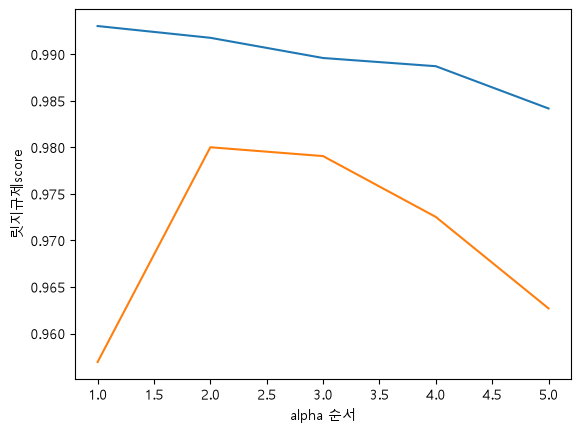

In [264]:
# 선그래프
no_list = [1,2,3,4,5]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('릿지규제score')
plt.show()

In [265]:
ridge = Ridge(alpha=alpha)
ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print('train정확도: ',score)
print('test정확도: ',score2)

train정확도:  0.9841843235774494
test정확도:  0.9627042641050291


In [266]:
# 다항식을 만든 형태 확인 가능
# print(poly.get_feature_names_out())

In [267]:
# degree = 2 /특성을 9개로 변경해서 예측
# 데이터 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)
# 데이터 예측
predict = lr.predict(test_poly)
print('예측: ',predict)
# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train정확도: ',score)
print('test정확도: ',score2)

예측:  [  21.33375122   68.72308724  249.47847582  126.59354494  132.76211216
  791.58277631  353.70535283  175.47940845  848.64141036  101.8739826
 1154.13650864   54.05089986  258.76262593  276.79004649]
train정확도:  0.9953852031717493
test정확도:  0.9780184172675167
